# Traffic Volume Prediction Using Time and Weather Features

## Project Overview
This project aims to predict traffic volume using historical traffic,
time-related features, and weather conditions.

## Objectives
1. Understand historical traffic patterns.
2. Explore the relationship between weather and traffic volume.
3. Build Random Forest regression models.
4. Compare time-only and time-plus-weather models.
5. Evaluate model performance using appropriate metrics.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Path to the original dataset
DATA_PATH = "data/Metro_Interstate_Traffic_Volume.csv"

# Load the dataset
raw_df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Number of rows:", raw_df.shape[0])
print("Number of columns:", raw_df.shape[1])

Number of rows: 48204
Number of columns: 9


In [4]:
# Display first five records
raw_df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [5]:
# Display column names and data types
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 3.3 MB


In [6]:
# Statistical summary
raw_df.describe(include="all")

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
count,61,48204.000000,48204.000000,48204.000000,48204.000000,48204,48204,48204,48204.000000
unique,11,NaN,NaN,NaN,NaN,11,38,40575,NaN
top,Labor Day,NaN,NaN,NaN,NaN,Clouds,sky is clear,2013-04-18 22:00:00,NaN
freq,7,NaN,NaN,NaN,NaN,15164,11665,6,NaN
mean,NaN,281.205870,0.334264,0.000222,49.362231,NaN,NaN,NaN,3259.818355
std,NaN,13.338232,44.789133,0.008168,39.015750,NaN,NaN,NaN,1986.860670
min,NaN,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,0.000000
25%,NaN,272.160000,0.000000,0.000000,1.000000,NaN,NaN,NaN,1193.000000
50%,NaN,282.450000,0.000000,0.000000,64.000000,NaN,NaN,NaN,3380.000000
75%,NaN,291.806000,0.000000,0.000000,90.000000,NaN,NaN,NaN,4933.000000


## Stage 3: Data Quality Audit

In this stage, we examine the dataset for:
- Missing values
- Duplicate records
- Duplicate timestamps
- Invalid timestamps
- Unusual numerical values

In [7]:
# Count missing values in each column
missing_values = raw_df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

# Percentage of missing values
missing_percentage = (missing_values / len(raw_df)) * 100

print("\nMissing value percentage:")
print(missing_percentage.round(2))

Missing values in each column:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

Missing value percentage:
holiday                99.87
temp                    0.00
rain_1h                 0.00
snow_1h                 0.00
clouds_all              0.00
weather_main            0.00
weather_description     0.00
date_time               0.00
traffic_volume          0.00
dtype: float64


In [8]:
# Count exact duplicate rows
duplicate_rows = raw_df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_rows)

Number of exact duplicate rows: 17


In [9]:
# Count repeated timestamps
duplicate_timestamps = raw_df["date_time"].duplicated().sum()

print("Number of repeated timestamps:", duplicate_timestamps)

Number of repeated timestamps: 7629


In [10]:
# Statistical summary of numerical columns
raw_df.describe()

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,7280.000000


In [11]:
# Examine rainfall distribution
rain_percentiles = raw_df["rain_1h"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
)

print(rain_percentiles)

0.500     0.00000
0.750     0.00000
0.900     0.00000
0.950     0.30000
0.990     3.27000
0.999    13.60346
Name: rain_1h, dtype: float64


In [12]:
# Display the 10 highest rainfall observations
raw_df.nlargest(10, "rain_1h")[
    ["date_time", "rain_1h", "weather_main",
     "weather_description", "traffic_volume"]
]

,date_time,rain_1h,weather_main,weather_description,traffic_volume
24872,2016-07-11 17:00:00,9831.30,Rain,very heavy rain,5535
8247,2013-08-07 02:00:00,55.63,Rain,very heavy rain,315
7179,2013-06-24 11:00:00,44.45,Rain,very heavy rain,4802
25779,2016-08-16 17:00:00,31.75,Rain,very heavy rain,4913
10806,2013-12-19 23:00:00,28.70,Rain,very heavy rain,1190
10807,2013-12-19 23:00:00,28.70,Snow,light snow,1190
16504,2015-07-13 00:00:00,27.57,Rain,very heavy rain,492
16505,2015-07-13 00:00:00,27.57,Thunderstorm,proximity thunderstorm,492
16506,2015-07-13 00:00:00,27.57,Mist,mist,492
17437,2015-08-16 21:00:00,25.46,Rain,very heavy rain,2118


In [13]:
timestamp_counts = raw_df["date_time"].value_counts()

print("Number of unique timestamps:",
      raw_df["date_time"].nunique())

print("Timestamps with multiple observations:",
      (timestamp_counts > 1).sum())

print("\nMaximum observations for a single timestamp:",
      timestamp_counts.max())

Number of unique timestamps: 40575
Timestamps with multiple observations: 5445

Maximum observations for a single timestamp: 6


In [14]:
# Remove exact duplicates temporarily for this audit
audit_df = raw_df.drop_duplicates().copy()

# Group records by timestamp
grouped = audit_df.groupby("date_time")

# Check traffic volume conflicts
traffic_conflicts = grouped["traffic_volume"].nunique()

print("Timestamps with conflicting traffic volumes:",
      (traffic_conflicts > 1).sum())

# Check numerical weather conflicts
weather_columns = [
    "temp", "rain_1h", "snow_1h", "clouds_all"
]

for column in weather_columns:
    conflicts = grouped[column].nunique()
    print(f"{column}: {(conflicts > 1).sum()} conflicting timestamps")

Timestamps with conflicting traffic volumes: 0
temp: 78 conflicting timestamps
rain_1h: 9 conflicting timestamps
snow_1h: 0 conflicting timestamps
clouds_all: 32 conflicting timestamps


## Stage 4: Data Cleaning

We will:
1. Remove exact duplicate records.
2. Convert date_time into datetime format.
3. Consolidate repeated timestamps.
4. Aggregate numerical weather measurements.
5. Preserve distinct weather categories.
6. Handle missing holiday values.
7. Verify the cleaned dataset.

In [15]:
# Create a copy of the original dataset
df = raw_df.copy()

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("Original shape:", raw_df.shape)
print("Shape after removing exact duplicates:", df.shape)
print("Rows removed:", len(raw_df) - len(df))

Original shape: (48204, 9)
Shape after removing exact duplicates: (48187, 9)
Rows removed: 17


In [16]:
# Convert date_time column to datetime format
df["date_time"] = pd.to_datetime(df["date_time"])

# Verify conversion
print("Data type:", df["date_time"].dtype)

# Check for invalid timestamps
print("Invalid timestamps:", df["date_time"].isna().sum())

# Display first five timestamps
print(df["date_time"].head())

Data type: datetime64[us]
Invalid timestamps: 0
0   2012-10-02 09:00:00
1   2012-10-02 10:00:00
2   2012-10-02 11:00:00
3   2012-10-02 12:00:00
4   2012-10-02 13:00:00
Name: date_time, dtype: datetime64[us]


In [17]:
# Define aggregation functions
aggregation_rules = {
    "holiday": lambda x: ", ".join(sorted(set(x.dropna()))),
    "temp": "median",
    "rain_1h": "median",
    "snow_1h": "median",
    "clouds_all": "median",
    "weather_main": lambda x: ", ".join(sorted(set(x.dropna()))),
    "weather_description": lambda x: ", ".join(sorted(set(x.dropna()))),
    "traffic_volume": "first"
}

# Group by timestamp and aggregate
df = (
    df.groupby("date_time", as_index=False)
      .agg(aggregation_rules)
)

print("Shape after consolidating timestamps:", df.shape)
print("Unique timestamps:", df["date_time"].nunique())
print("Duplicate timestamps remaining:", df["date_time"].duplicated().sum())

Shape after consolidating timestamps: (40575, 9)
Unique timestamps: 40575
Duplicate timestamps remaining: 0


In [18]:
# Replace empty holiday values with "None"
df["holiday"] = df["holiday"].replace("", "None")

# Fill remaining missing values
df["holiday"] = df["holiday"].fillna("None")

# Verify
print("Missing holiday values:", df["holiday"].isna().sum())

print("\nHoliday distribution:")
print(df["holiday"].value_counts())

Missing holiday values: 0

Holiday distribution:
holiday
None                         40522
Columbus Day                     5
Veterans Day                     5
Thanksgiving Day                 5
Christmas Day                    5
New Years Day                    5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Labor Day                        5
Martin Luther King Jr Day        3
Name: count, dtype: int64


In [19]:
print("Rainfall statistics:")
print(df["rain_1h"].describe())

print("\nHighest 10 rainfall values:")
print(df.nlargest(10, "rain_1h")[["date_time", "rain_1h", "traffic_volume"]])

Rainfall statistics:
count    40575.000000
mean         0.318632
std         48.812640
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       9831.300000
Name: rain_1h, dtype: float64

Highest 10 rainfall values:
                date_time  rain_1h  traffic_volume
21224 2016-07-11 17:00:00  9831.30            5535
6854  2013-08-07 02:00:00    55.63             315
5850  2013-06-24 11:00:00    44.45            4802
22082 2016-08-16 17:00:00    31.75            4913
9127  2013-12-19 23:00:00    28.70            1190
14333 2015-07-13 00:00:00    27.57             492
15166 2015-08-16 21:00:00    25.46            2118
6317  2013-07-14 06:00:00    25.32             958
14169 2015-07-06 03:00:00    23.80             346
6318  2013-07-14 07:00:00    21.42            1745


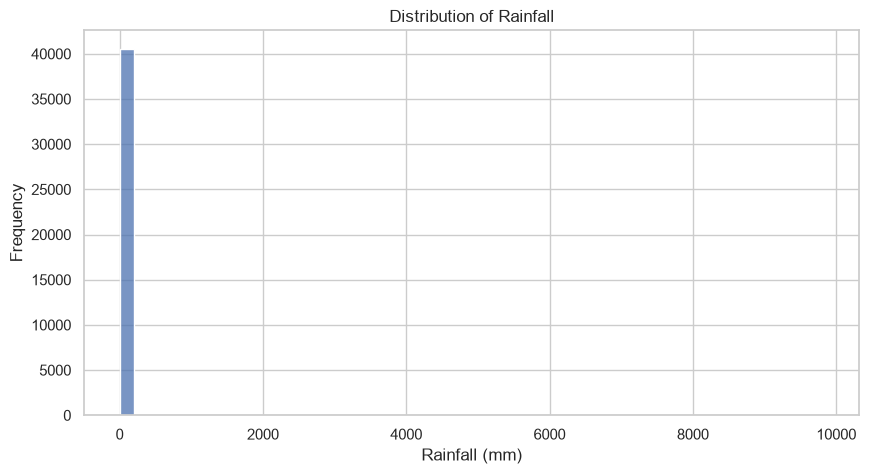

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(df["rain_1h"], bins=50)

plt.title("Distribution of Rainfall")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")

plt.show()

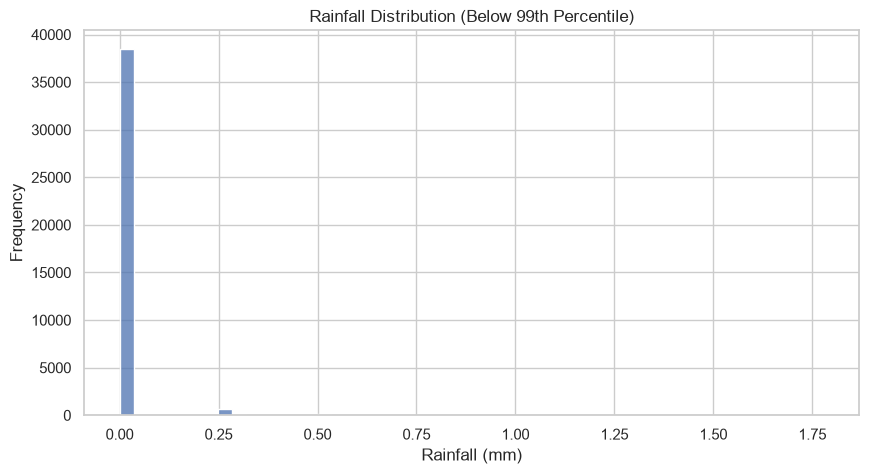

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df.loc[df["rain_1h"] <= df["rain_1h"].quantile(0.99), "rain_1h"],
    bins=50
)

plt.title("Rainfall Distribution (Below 99th Percentile)")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")

plt.show()

In [22]:
print(
    df["rain_1h"].describe(
        percentiles=[0.90, 0.95, 0.99, 0.999]
    )
)

count    40575.000000
mean         0.318632
std         48.812640
min          0.000000
90%          0.000000
95%          0.250000
99%          1.780000
99.9%       10.096860
max       9831.300000
Name: rain_1h, dtype: float64


In [23]:
# Sort observations chronologically
df = df.sort_values("date_time").reset_index(drop=True)

# Final dataset information
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate timestamps:",
      df["date_time"].duplicated().sum())

print("\nDate range:")
print("Start:", df["date_time"].min())
print("End:", df["date_time"].max())

print("\nTraffic volume statistics:")
print(df["traffic_volume"].describe())

print("\nFirst five cleaned records:")
display(df.head())

Final dataset shape: (40575, 9)

Missing values:
date_time              0
holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
traffic_volume         0
dtype: int64

Duplicate timestamps: 0

Date range:
Start: 2012-10-02 09:00:00
End: 2018-09-30 23:00:00

Traffic volume statistics:
count    40575.000000
mean      3290.650474
std       1984.772909
min          0.000000
25%       1248.500000
50%       3427.000000
75%       4952.000000
max       7280.000000
Name: traffic_volume, dtype: float64

First five cleaned records:


,date_time,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,traffic_volume
0,2012-10-02 09:00:00,None,288.28,0.0,0.0,40.0,Clouds,scattered clouds,5545
1,2012-10-02 10:00:00,None,289.36,0.0,0.0,75.0,Clouds,broken clouds,4516
2,2012-10-02 11:00:00,None,289.58,0.0,0.0,90.0,Clouds,overcast clouds,4767
3,2012-10-02 12:00:00,None,290.13,0.0,0.0,90.0,Clouds,overcast clouds,5026
4,2012-10-02 13:00:00,None,291.14,0.0,0.0,75.0,Clouds,broken clouds,4918


### Hourly Coverage Check

The cleaned data should contain one row per hour between the first and last timestamp. This check counts how many hours are missing and where the largest gaps are.
Missing hours do not affect the current models, which use only the time and weather of each row, but they matter for any future lag-based features.

In [ ]:
# Check for gaps in hourly coverage
full_range = pd.date_range(df["date_time"].min(), df["date_time"].max(), freq="h")
missing_hours = full_range.difference(df["date_time"])

print("Expected hourly rows:", len(full_range))
print("Actual rows:", len(df))
print("Missing hours:", len(missing_hours))
print(f"Coverage: {len(df) / len(full_range) * 100:.1f}%")

# Largest gaps between consecutive observations (in hours)
gap_hours = df["date_time"].diff().dt.total_seconds().div(3600)
largest = gap_hours.nlargest(10)
print("\nLargest gaps (hours) and where they end:")
print(pd.DataFrame({
    "gap_hours": largest,
    "gap_ends_at": df.loc[largest.index, "date_time"]
}))

## Stage 5: Exploratory Data Analysis

We explore traffic patterns across different times and weather conditions.

In [24]:
# Create a separate EDA DataFrame
eda_df = df.copy()

# Extract time-related information
eda_df["hour"] = eda_df["date_time"].dt.hour
eda_df["day_of_week"] = eda_df["date_time"].dt.dayofweek
eda_df["day_name"] = eda_df["date_time"].dt.day_name()
eda_df["month"] = eda_df["date_time"].dt.month
eda_df["month_name"] = eda_df["date_time"].dt.month_name()
eda_df["year"] = eda_df["date_time"].dt.year

print(eda_df[[
    "date_time", "hour", "day_of_week",
    "day_name", "month", "month_name", "year"
]].head())

            date_time  hour  day_of_week day_name  month month_name  year
0 2012-10-02 09:00:00     9            1  Tuesday     10    October  2012
1 2012-10-02 10:00:00    10            1  Tuesday     10    October  2012
2 2012-10-02 11:00:00    11            1  Tuesday     10    October  2012
3 2012-10-02 12:00:00    12            1  Tuesday     10    October  2012
4 2012-10-02 13:00:00    13            1  Tuesday     10    October  2012


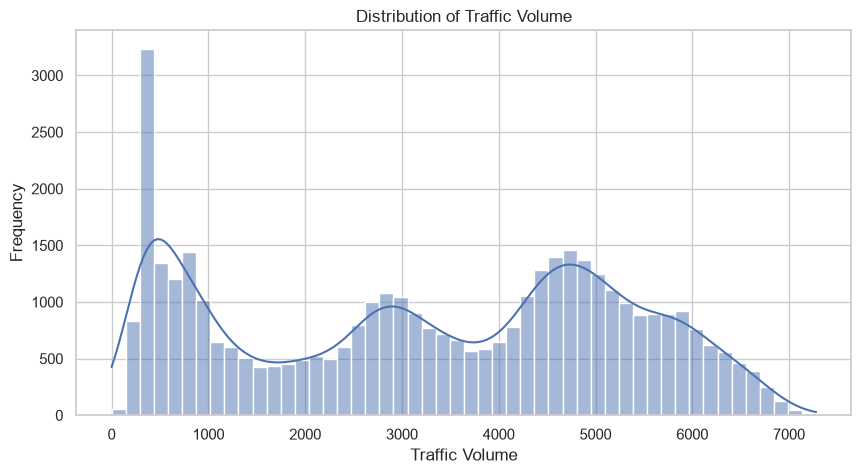

In [25]:
plt.figure(figsize=(10, 5))

sns.histplot(eda_df["traffic_volume"], bins=50, kde=True)

plt.title("Distribution of Traffic Volume")
plt.xlabel("Traffic Volume")
plt.ylabel("Frequency")

plt.show()

In [26]:
# Calculate average traffic volume for each hour
hourly_traffic = eda_df.groupby("hour")["traffic_volume"].mean()

print(hourly_traffic)

hour
0      844.854324
1      521.318713
2      392.637006
3      373.210306
4      701.317675
5     2103.667062
6     4172.058229
7     4769.831340
8     4593.599763
9     4394.778523
10    4204.876833
11    4498.458908
12    4739.118794
13    4741.578004
14    4957.022982
15    5271.737823
16    5708.614528
17    5350.830529
18    4306.467301
19    3311.021390
20    2869.703920
21    2699.360915
22    2224.418848
23    1490.710345
Name: traffic_volume, dtype: float64


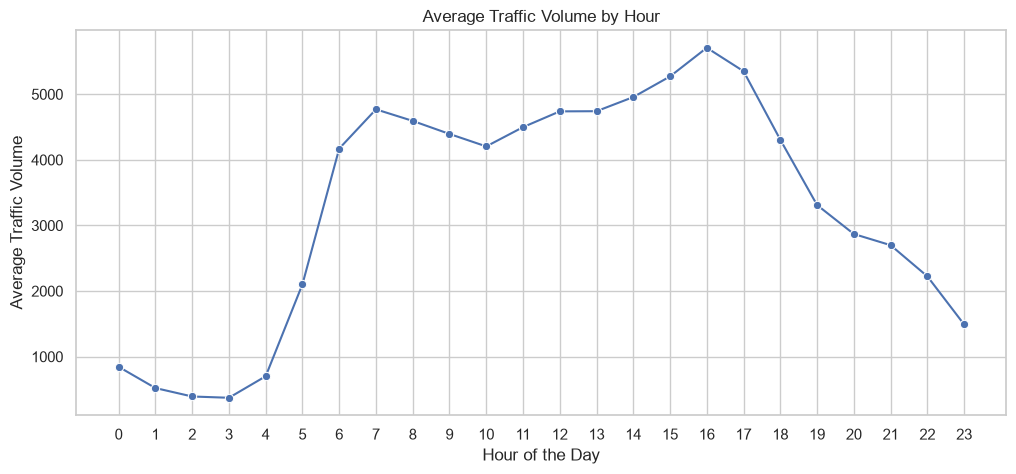

In [27]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_traffic.index,
    y=hourly_traffic.values,
    marker="o"
)

plt.title("Average Traffic Volume by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Traffic Volume")
plt.xticks(range(24))
plt.grid(True)

plt.show()

In [28]:
# Calculate average traffic by day of the week
daily_traffic = (
    eda_df.groupby("day_name")["traffic_volume"]
    .mean()
)

# Arrange days in calendar order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_traffic = daily_traffic.reindex(day_order)

print(daily_traffic)

day_name
Monday       3313.560614
Tuesday      3534.717166
Wednesday    3608.276064
Thursday     3653.914611
Friday       3674.777608
Saturday     2822.564661
Sunday       2426.249484
Name: traffic_volume, dtype: float64


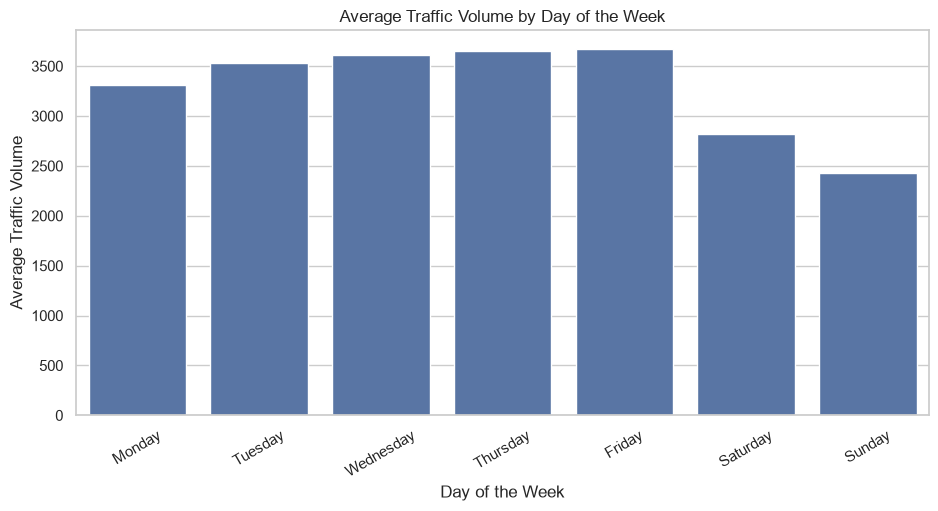

In [29]:
plt.figure(figsize=(11, 5))

sns.barplot(
    x=daily_traffic.index,
    y=daily_traffic.values
)

plt.title("Average Traffic Volume by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=30)

plt.show()

In [30]:
# Calculate average traffic volume by month
monthly_traffic = (
    eda_df.groupby("month_name")["traffic_volume"]
    .mean()
)

# Arrange months in calendar order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_traffic = monthly_traffic.reindex(month_order)

print(monthly_traffic)

month_name
January      3060.224270
February     3230.793492
March        3382.463363
April        3373.742464
May          3378.407151
June         3421.882083
July         3237.695093
August       3430.323887
September    3318.849273
October      3388.037223
November     3215.941006
December     3040.194486
Name: traffic_volume, dtype: float64


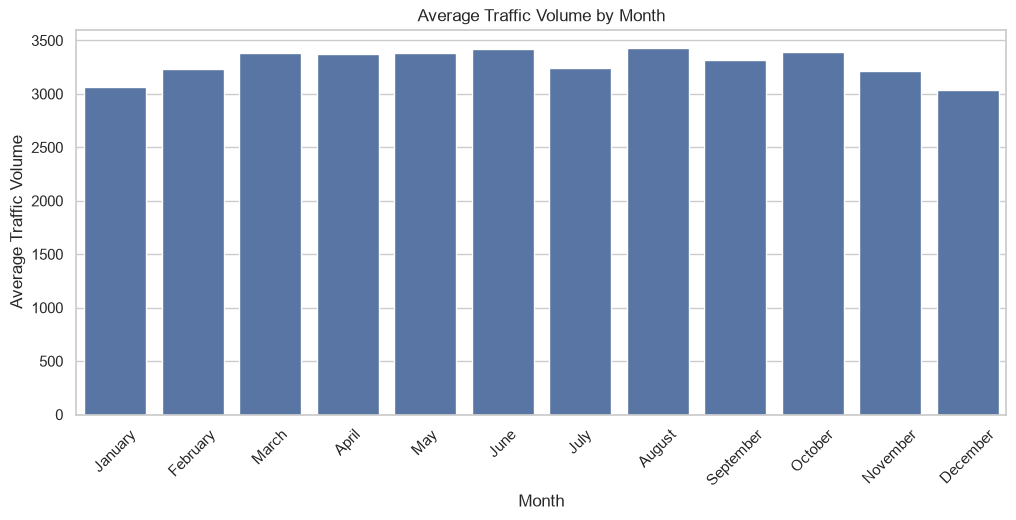

In [31]:
plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_traffic.index,
    y=monthly_traffic.values
)

plt.title("Average Traffic Volume by Month")
plt.xlabel("Month")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=45)

plt.show()

In [32]:
# Calculate average traffic volume by weather category
weather_traffic = (
    eda_df.groupby("weather_main")["traffic_volume"]
    .mean()
    .sort_values(ascending=False)
)

print(weather_traffic)

weather_main
Fog, Rain, Thunderstorm                    6667.000000
Fog, Mist, Thunderstorm                    5918.000000
Clouds, Haze                               5760.500000
Haze, Mist, Rain, Smoke                    5605.500000
Haze, Mist, Thunderstorm                   5323.000000
Drizzle, Fog, Rain, Thunderstorm           4916.000000
Drizzle, Fog, Rain, Snow                   4686.000000
Drizzle, Haze, Mist, Rain, Smoke           4597.500000
Drizzle, Haze, Rain                        4552.875000
Smoke                                      4443.000000
Drizzle, Haze                              4406.000000
Drizzle, Snow                              4298.444444
Drizzle, Fog, Mist, Rain, Snow             4290.750000
Haze, Mist, Rain                           4179.642857
Clear, Clouds                              4144.285714
Haze, Rain, Thunderstorm                   4121.000000
Drizzle, Haze, Mist                        4095.909091
Drizzle, Haze, Mist, Rain, Thunderstorm    4075.5000

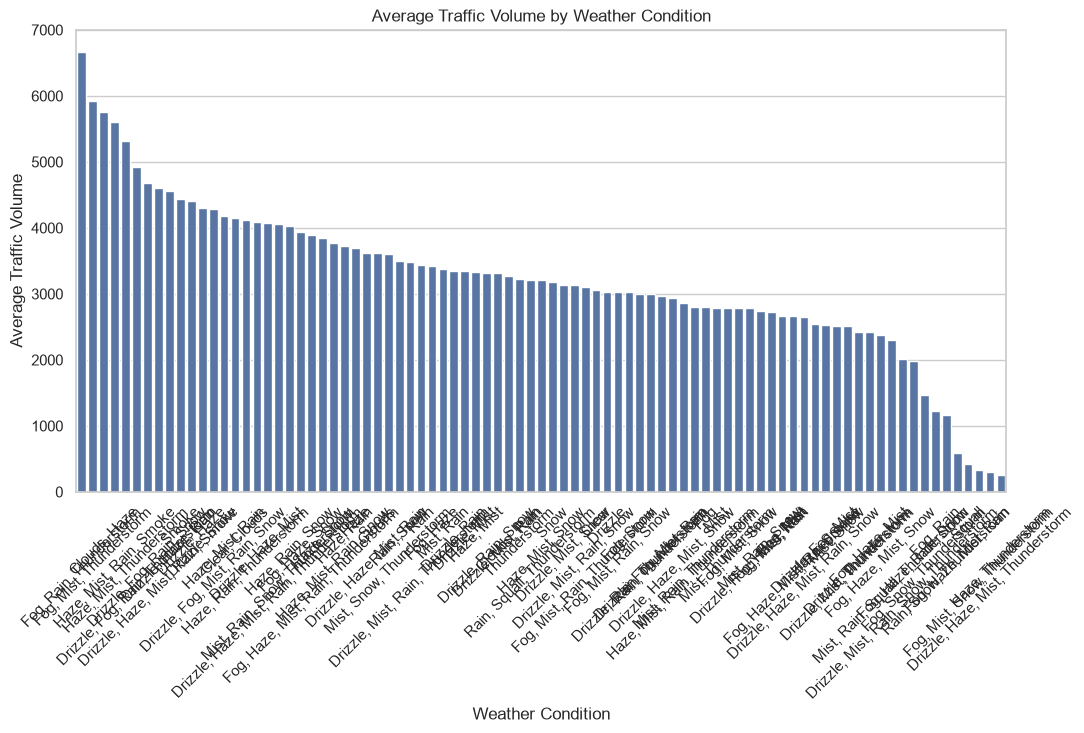

In [33]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=weather_traffic.index,
    y=weather_traffic.values
)

plt.title("Average Traffic Volume by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=45)

plt.show()

In [34]:
# Split combined weather categories
weather_df = eda_df[
    ["date_time", "weather_main", "traffic_volume"]
].copy()

weather_df["weather_main"] = (
    weather_df["weather_main"].str.split(", ")
)

# Expand individual weather categories into separate rows
weather_df = weather_df.explode("weather_main")

print("Individual weather categories:")
print(weather_df["weather_main"].unique())

Individual weather categories:
<StringArray>
[      'Clouds',        'Clear',         'Rain',      'Drizzle',
         'Mist',         'Haze',          'Fog', 'Thunderstorm',
         'Snow',       'Squall',        'Smoke']
Length: 11, dtype: str


In [35]:
# Calculate average traffic and number of observations
weather_analysis = (
    weather_df.groupby("weather_main")
    .agg(
        average_traffic=("traffic_volume", "mean"),
        observation_count=("traffic_volume", "count")
    )
    .sort_values("average_traffic", ascending=False)
)

print(weather_analysis)

              average_traffic  observation_count
weather_main                                    
Clouds            3616.947709              15127
Haze              3501.285504               1359
Rain              3322.444185               5563
Drizzle           3286.561942               1792
Smoke             3237.650000                 20
Clear             3055.735173              13371
Thunderstorm      3009.916832               1010
Snow              3009.327013               2795
Mist              2933.081987               5940
Fog               2703.720395                912
Squall            2061.750000                  4


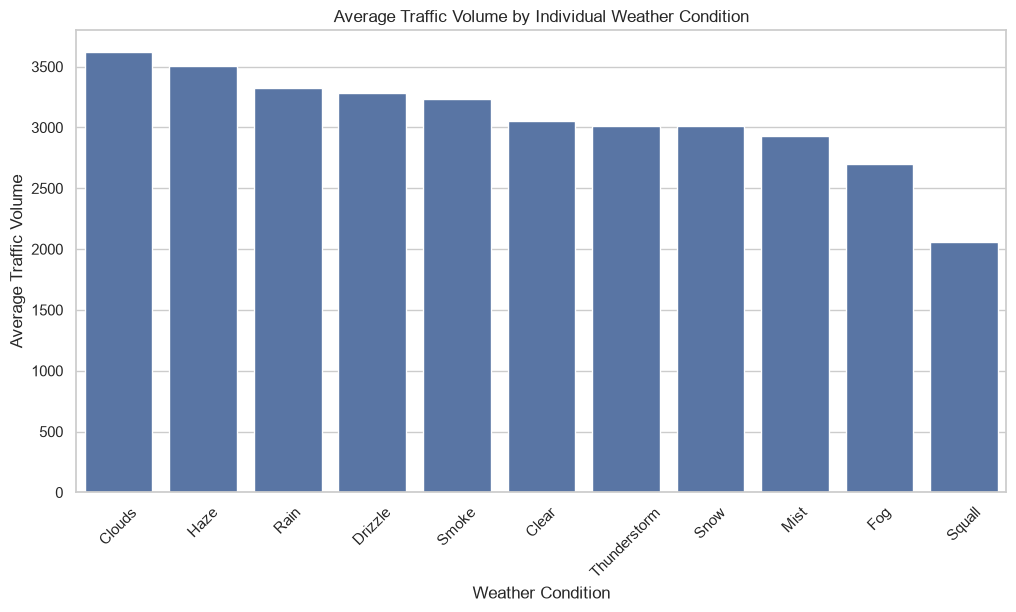

In [36]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=weather_analysis.reset_index(),
    x="weather_main",
    y="average_traffic"
)

plt.title("Average Traffic Volume by Individual Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=45)

plt.show()

In [37]:
# Select numerical columns
numerical_columns = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume",
    "hour",
    "day_of_week",
    "month"
]

# Calculate correlation matrix
correlation_matrix = eda_df[numerical_columns].corr()

print(correlation_matrix["traffic_volume"].sort_values(ascending=False))

traffic_volume    1.000000
hour              0.355237
temp              0.136884
clouds_all        0.078347
rain_1h           0.005402
snow_1h          -0.002086
month            -0.004517
day_of_week      -0.144460
Name: traffic_volume, dtype: float64


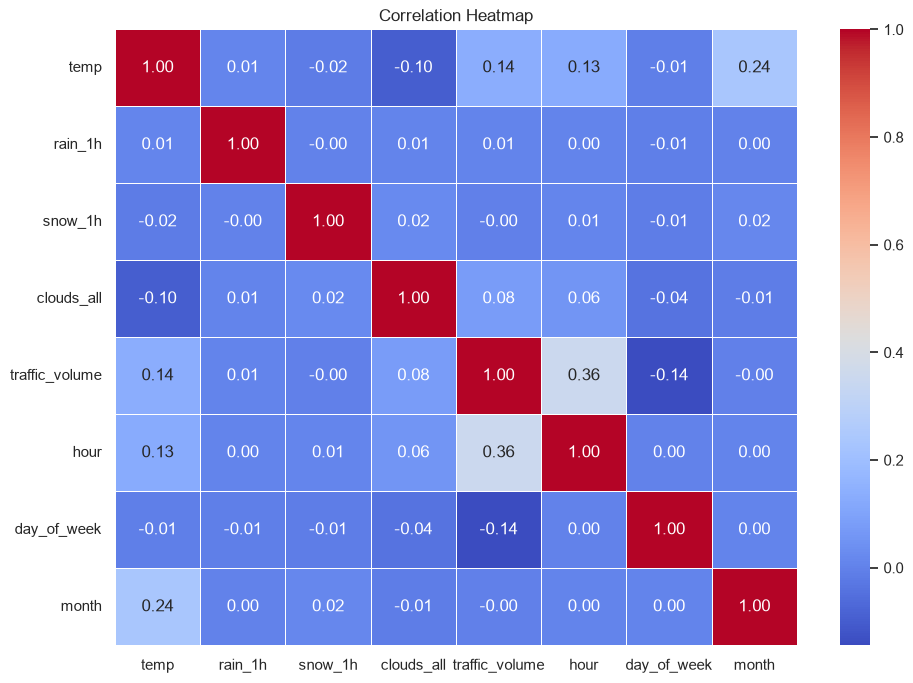

In [38]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

## Stage 6: Feature Engineering

We extract useful time-related features and create cyclical
representations of hour, day of week, and month.

In [41]:
# Create modelling dataset
model_df = df.copy()

# Extract time-based features
model_df["hour"] = model_df["date_time"].dt.hour
model_df["day_of_week"] = model_df["date_time"].dt.dayofweek
model_df["month"] = model_df["date_time"].dt.month
model_df["year"] = model_df["date_time"].dt.year

# Weekend indicator: Saturday = 5, Sunday = 6
model_df["is_weekend"] = (
    model_df["day_of_week"] >= 5
).astype(int)

print(model_df.head())

            date_time holiday    temp  rain_1h  snow_1h  clouds_all  \
0 2012-10-02 09:00:00    None  288.28      0.0      0.0        40.0   
1 2012-10-02 10:00:00    None  289.36      0.0      0.0        75.0   
2 2012-10-02 11:00:00    None  289.58      0.0      0.0        90.0   
3 2012-10-02 12:00:00    None  290.13      0.0      0.0        90.0   
4 2012-10-02 13:00:00    None  291.14      0.0      0.0        75.0   

  weather_main weather_description  traffic_volume  hour  day_of_week  month  \
0       Clouds    scattered clouds            5545     9            1     10   
1       Clouds       broken clouds            4516    10            1     10   
2       Clouds     overcast clouds            4767    11            1     10   
3       Clouds     overcast clouds            5026    12            1     10   
4       Clouds       broken clouds            4918    13            1     10   

   year  is_weekend  
0  2012           0  
1  2012           0  
2  2012           0  
3  2

In [42]:
# Cyclical encoding for hour
model_df["hour_sin"] = np.sin(
    2 * np.pi * model_df["hour"] / 24
)

model_df["hour_cos"] = np.cos(
    2 * np.pi * model_df["hour"] / 24
)

# Cyclical encoding for day of week
model_df["day_sin"] = np.sin(
    2 * np.pi * model_df["day_of_week"] / 7
)

model_df["day_cos"] = np.cos(
    2 * np.pi * model_df["day_of_week"] / 7
)

# Cyclical encoding for month
model_df["month_sin"] = np.sin(
    2 * np.pi * (model_df["month"] - 1) / 12
)

model_df["month_cos"] = np.cos(
    2 * np.pi * (model_df["month"] - 1) / 12
)

print("Cyclical features created successfully!")

Cyclical features created successfully!


In [43]:
engineered_features = [
    "hour",
    "day_of_week",
    "month",
    "year",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "month_sin",
    "month_cos"
]

display(model_df[engineered_features].head(10))

,hour,day_of_week,month,year,is_weekend,hour_sin,hour_cos,day_sin,day_cos,month_sin,month_cos
0,9,1,10,2012,0,7.071068e-01,-7.071068e-01,0.781831,0.62349,-1.0,-1.836970e-16
1,10,1,10,2012,0,5.000000e-01,-8.660254e-01,0.781831,0.62349,-1.0,-1.836970e-16
2,11,1,10,2012,0,2.588190e-01,-9.659258e-01,0.781831,0.62349,-1.0,-1.836970e-16
3,12,1,10,2012,0,1.224647e-16,-1.000000e+00,0.781831,0.62349,-1.0,-1.836970e-16
4,13,1,10,2012,0,-2.588190e-01,-9.659258e-01,0.781831,0.62349,-1.0,-1.836970e-16
5,14,1,10,2012,0,-5.000000e-01,-8.660254e-01,0.781831,0.62349,-1.0,-1.836970e-16
6,15,1,10,2012,0,-7.071068e-01,-7.071068e-01,0.781831,0.62349,-1.0,-1.836970e-16
7,16,1,10,2012,0,-8.660254e-01,-5.000000e-01,0.781831,0.62349,-1.0,-1.836970e-16
8,17,1,10,2012,0,-9.659258e-01,-2.588190e-01,0.781831,0.62349,-1.0,-1.836970e-16
9,18,1,10,2012,0,-1.000000e+00,-1.836970e-16,0.781831,0.62349,-1.0,-1.836970e-16


In [44]:
print("Number of rows:", len(model_df))

print("\nNew engineered columns:")
print(engineered_features)

print("\nMissing values in engineered features:")
print(model_df[engineered_features].isnull().sum())

print("\nWeekend distribution:")
print(model_df["is_weekend"].value_counts())

Number of rows: 40575

New engineered columns:
['hour', 'day_of_week', 'month', 'year', 'is_weekend', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'month_sin', 'month_cos']

Missing values in engineered features:
hour           0
day_of_week    0
month          0
year           0
is_weekend     0
hour_sin       0
hour_cos       0
day_sin        0
day_cos        0
month_sin      0
month_cos      0
dtype: int64

Weekend distribution:
is_weekend
0    28979
1    11596
Name: count, dtype: int64


### Weather Feature Preparation

We represent categorical weather information using multi-hot
encoding so that multiple weather conditions can be represented
simultaneously for a single timestamp.

In [45]:
# Define numerical and categorical weather columns

weather_numeric_features = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all"
]

weather_categorical_features = [
    "holiday",
    "weather_main",
    "weather_description"
]

print("Numerical weather features:")
print(weather_numeric_features)

print("\nCategorical weather features:")
print(weather_categorical_features)

Numerical weather features:
['temp', 'rain_1h', 'snow_1h', 'clouds_all']

Categorical weather features:
['holiday', 'weather_main', 'weather_description']


In [46]:
for column in weather_categorical_features:
    print(f"\n{column}")
    print("Number of unique categories:",
          model_df[column].nunique())
    print(model_df[column].value_counts().head(10))


holiday
Number of unique categories: 12
holiday
None                    40522
Columbus Day                5
Veterans Day                5
Thanksgiving Day            5
Christmas Day               5
New Years Day               5
Washingtons Birthday        5
Memorial Day                5
Independence Day            5
State Fair                  5
Name: count, dtype: int64

weather_main
Number of unique categories: 85
weather_main
Clouds                 15116
Clear                  13364
Rain                    2628
Mist                    1936
Snow                    1248
Mist, Snow               749
Mist, Rain               578
Drizzle, Mist, Rain      571
Drizzle, Rain            558
Fog, Mist                491
Name: count, dtype: int64

weather_description
Number of unique categories: 413
weather_description
sky is clear        11640
overcast clouds      5070
broken clouds        4645
scattered clouds     3447
few clouds           1944
mist                 1936
light rain          

### 7. Train-Test Split (80:20)

In this stage, we divide the cleaned dataset into training and testing sets using an **80:20 chronological split**.

- **Training set (80%):** Used to train the Random Forest models and learn traffic patterns from historical observations.
- **Testing set (20%):** Used to evaluate the trained models on observations from a later period that they have not previously seen.

Since this project involves time-dependent traffic data, we use a chronological split instead of random splitting.

This ensures that:
1. The training dataset contains earlier observations.
2. The testing dataset contains later observations.
3. Future observations are not used to train models that predict the past.

We will use the same training and testing periods for both the **Time-Only** and **Time + Weather** models to ensure a fair comparison.

In [47]:
# Define time-related features
time_features = [
    "hour",
    "day_of_week",
    "month",
    "year",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "month_sin",
    "month_cos"
]

# Define numerical weather features
weather_numeric_features = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all"
]

# Define weather categorical features
weather_categorical_features = [
    "holiday",
    "weather_main"
]

# Define target
target = "traffic_volume"

print("Time features:", len(time_features))
print("Numerical weather features:", len(weather_numeric_features))
print("Categorical weather features:", len(weather_categorical_features))

Time features: 11
Numerical weather features: 4
Categorical weather features: 2


In [48]:
# Sort chronologically
model_df = model_df.sort_values("date_time").reset_index(drop=True)

# Calculate 80% split point
split_index = int(len(model_df) * 0.80)

# Split into training and testing
train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining period:")
print(train_df["date_time"].min(), "to", train_df["date_time"].max())

print("\nTesting period:")
print(test_df["date_time"].min(), "to", test_df["date_time"].max())

Training rows: 32460
Testing rows: 8115

Training period:
2012-10-02 09:00:00 to 2017-10-26 17:00:00

Testing period:
2017-10-26 18:00:00 to 2018-09-30 23:00:00


In [49]:
# Time-only feature sets
X_train_time = train_df[time_features].copy()
X_test_time = test_df[time_features].copy()

# Time + Weather feature sets
weather_features = (
    time_features
    + weather_numeric_features
    + weather_categorical_features
)

X_train_weather = train_df[weather_features].copy()
X_test_weather = test_df[weather_features].copy()

# Target variables
y_train = train_df[target].copy()
y_test = test_df[target].copy()

print("Time-only training shape:", X_train_time.shape)
print("Time-only testing shape:", X_test_time.shape)

print("Time + Weather training shape:", X_train_weather.shape)
print("Time + Weather testing shape:", X_test_weather.shape)

print("Target training shape:", y_train.shape)
print("Target testing shape:", y_test.shape)

Time-only training shape: (32460, 11)
Time-only testing shape: (8115, 11)
Time + Weather training shape: (32460, 17)
Time + Weather testing shape: (8115, 17)
Target training shape: (32460,)
Target testing shape: (8115,)


### 8. Preprocessing

In this stage, we prepare the training and testing features for machine learning.

The preprocessing operations include:

- **Missing value imputation:** Replace missing numerical values with the median and categorical values with the most frequent category.
- **Categorical encoding:** Convert categorical weather information into numerical features using appropriate encoding techniques.
- **Outlier treatment:** Cap extreme rainfall values using the 99th percentile calculated from the training data.
- **Feature transformation:** Apply consistent preprocessing to training, validation and testing data.

We use Scikit-learn's `Pipeline` and `ColumnTransformer` to combine these operations.

This approach ensures that preprocessing parameters are learned only from the training portion of each fold during cross-validation, preventing data leakage.

In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin

In [51]:
class RainfallCapper(BaseEstimator, TransformerMixin):

    def __init__(self, column="rain_1h", percentile=99):
        self.column = column
        self.percentile = percentile

    def fit(self, X, y=None):
        self.upper_limit_ = X[self.column].quantile(
            self.percentile / 100
        )
        return self

    def transform(self, X):
        X = X.copy()
        X[self.column] = X[self.column].clip(
            upper=self.upper_limit_
        )
        return X

In [52]:
class MultiHotWeatherEncoder(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        weather_labels = set()

        for value in X.iloc[:, 0].dropna():
            labels = [label.strip() for label in value.split(",")]
            weather_labels.update(labels)

        self.classes_ = sorted(weather_labels)
        self.label_to_index_ = {
            label: index
            for index, label in enumerate(self.classes_)
        }

        return self

    def transform(self, X):
        result = np.zeros(
            (len(X), len(self.classes_)),
            dtype=int
        )

        for row_index, value in enumerate(X.iloc[:, 0]):
            if pd.isna(value):
                continue

            labels = [label.strip() for label in value.split(",")]

            for label in labels:
                if label in self.label_to_index_:
                    column_index = self.label_to_index_[label]
                    result[row_index, column_index] = 1

        return result

    def get_feature_names_out(self, input_features=None):
        return np.array([
            f"weather_{label}" for label in self.classes_
        ])

In [53]:
time_features = [
    "hour", "day_of_week", "month", "year", "is_weekend",
    "hour_sin", "hour_cos", "day_sin", "day_cos",
    "month_sin", "month_cos"
]

weather_numeric_features = [
    "temp", "rain_1h", "snow_1h", "clouds_all"
]

holiday_features = ["holiday"]
weather_condition_features = ["weather_main"]

print("Time features:", len(time_features))
print("Weather numerical features:", len(weather_numeric_features))
print("Holiday features:", len(holiday_features))
print("Weather condition features:", len(weather_condition_features))

Time features: 11
Weather numerical features: 4
Holiday features: 1
Weather condition features: 1


In [54]:
time_preprocessor = ColumnTransformer(
    transformers=[
        (
            "time",
            SimpleImputer(strategy="median"),
            time_features
        )
    ],
    remainder="drop"
)

print("Time-only preprocessor created successfully!")

Time-only preprocessor created successfully!


In [55]:
weather_preprocessor = Pipeline(
    steps=[
        (
            "rainfall_capper",
            RainfallCapper(
                column="rain_1h",
                percentile=99
            )
        ),
        (
            "features",
            ColumnTransformer(
                transformers=[
                    (
                        "time",
                        SimpleImputer(strategy="median"),
                        time_features
                    ),
                    (
                        "weather_numeric",
                        SimpleImputer(strategy="median"),
                        weather_numeric_features
                    ),
                    (
                        "holiday",
                        Pipeline(
                            steps=[
                                ("imputer", SimpleImputer(strategy="most_frequent")),
                                ("encoder", OneHotEncoder(handle_unknown="ignore"))
                            ]
                        ),
                        holiday_features
                    ),
                    (
                        "weather_conditions",
                        MultiHotWeatherEncoder(),
                        weather_condition_features
                    )
                ],
                remainder="drop"
            )
        )
    ]
)

print("Time-plus-weather preprocessor created successfully!")

Time-plus-weather preprocessor created successfully!


In [56]:
print("Time-only preprocessor:")
print(time_preprocessor)

print("\nTime-plus-weather preprocessor:")
print(weather_preprocessor)

Time-only preprocessor:
ColumnTransformer(transformers=[('time', SimpleImputer(strategy='median'),
                                 ['hour', 'day_of_week', 'month', 'year',
                                  'is_weekend', 'hour_sin', 'hour_cos',
                                  'day_sin', 'day_cos', 'month_sin',
                                  'month_cos'])])

Time-plus-weather preprocessor:
Pipeline(steps=[('rainfall_capper', RainfallCapper()),
                ('features',
                 ColumnTransformer(transformers=[('time',
                                                  SimpleImputer(strategy='median'),
                                                  ['hour', 'day_of_week',
                                                   'month', 'year',
                                                   'is_weekend', 'hour_sin',
                                                   'hour_cos', 'day_sin',
                                                   'day_cos', 'month_sin',
         

In [57]:
time_model = Pipeline(
    steps=[
        ("preprocessor", time_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Time-only Random Forest model created successfully!")

Time-only Random Forest model created successfully!


In [58]:
time_model.fit(X_train_time, y_train)

print("Time-only Random Forest model trained successfully!")

Time-only Random Forest model trained successfully!


In [59]:
time_model.fit(X_train_time, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['hour','day_of_week','month',...,'day_cos','month_sin','month_cos']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('time', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatena

In [60]:
y_pred_time = time_model.predict(X_test_time)

print("Predictions generated successfully!")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_time[:10])

Predictions generated successfully!

First 10 actual values:
[4853 3763 3222 3761 3218 1617  685  435  278  377]

First 10 predicted values:
[4941.84490476 3751.94832143 3223.76767857 2884.08602381 2146.00265873
 1335.23131746  700.24304762  415.40825397  303.89666667  355.17775   ]


In [61]:
mae_time = mean_absolute_error(y_test, y_pred_time)

rmse_time = np.sqrt(
    mean_squared_error(y_test, y_pred_time)
)

r2_time = r2_score(y_test, y_pred_time)

print("Time-only Random Forest Performance")
print("------------------------------------")
print(f"MAE  : {mae_time:.2f}")
print(f"RMSE : {rmse_time:.2f}")
print(f"R²   : {r2_time:.4f}")

Time-only Random Forest Performance
------------------------------------
MAE  : 281.92
RMSE : 492.68
R²   : 0.9375


In [62]:
weather_model = Pipeline(
    steps=[
        ("preprocessor", weather_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Time-plus-weather Random Forest model created successfully!")

Time-plus-weather Random Forest model created successfully!


In [63]:
weather_model.fit(X_train_weather, y_train)

print("Time-plus-weather Random Forest model trained successfully!")

Time-plus-weather Random Forest model trained successfully!


In [64]:
y_pred_weather = weather_model.predict(X_test_weather)

print("Predictions generated successfully!")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_weather[:10])

Predictions generated successfully!

First 10 actual values:
[4853 3763 3222 3761 3218 1617  685  435  278  377]

First 10 predicted values:
[4935.73 3558.74 3020.34 3016.56 2223.78 1397.41  738.86  486.7   415.82
  359.16]


In [65]:
mae_weather = mean_absolute_error(y_test, y_pred_weather)

rmse_weather = np.sqrt(
    mean_squared_error(y_test, y_pred_weather)
)

r2_weather = r2_score(y_test, y_pred_weather)

print("Time-plus-weather Random Forest Performance")
print("--------------------------------------------")
print(f"MAE  : {mae_weather:.2f}")
print(f"RMSE : {rmse_weather:.2f}")
print(f"R²   : {r2_weather:.4f}")

Time-plus-weather Random Forest Performance
--------------------------------------------
MAE  : 281.51
RMSE : 486.55
R²   : 0.9390


### 9. Random Forest Regression — Initial Model Results

Two Random Forest regression models were trained and evaluated using the same chronological 80:20 train-test split.

**Model 1: Time-only Random Forest**

This model uses 11 engineered time-based features to predict traffic volume.

- MAE: 281.92
- RMSE: 492.68
- R²: 0.9375

**Model 2: Time-plus-weather Random Forest**

This model uses time-based features along with numerical and categorical weather information.

- MAE: 281.51
- RMSE: 486.55
- R²: 0.9390

**Initial Comparison and Observation**

The time-plus-weather model achieved slightly better performance than the time-only model across all three evaluation metrics.

The RMSE decreased by approximately 1.24%, while the R² score increased from 0.9375 to 0.9390.

These results suggest that weather features provide some additional predictive information. However, the improvement is relatively small, indicating that time-based features account for much of the predictive signal in this dataset.

Further evaluation and hyperparameter tuning will be performed before drawing final conclusions.

In [66]:
RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

### 10. Hyperparameter Tuning

In this stage, we optimize the Random Forest models by testing different combinations of hyperparameters.

We use **GridSearchCV** to evaluate different parameter combinations and identify the combination that performs best during cross-validation.

Since our dataset contains chronological traffic observations, we use **TimeSeriesSplit** instead of ordinary random cross-validation.

This ensures that each validation fold contains observations occurring after its corresponding training data.

Hyperparameter tuning is performed using only the training dataset. The test dataset remains untouched until the final evaluation.

The following hyperparameters will be investigated:

- `n_estimators`: Number of trees in the Random Forest.
- `max_depth`: Maximum depth of each decision tree.
- `min_samples_split`: Minimum number of samples required to split an internal node.
- `min_samples_leaf`: Minimum number of samples required at a leaf node.

In [67]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

In [68]:
tscv = TimeSeriesSplit(n_splits=3)

print("Number of cross-validation splits:", tscv.get_n_splits())

Number of cross-validation splits: 3


In [70]:
param_grid = {
    "regressor__n_estimators": [100, 200],
    "regressor__max_depth": [15, 25, None],
    "regressor__min_samples_split": [2, 5],
    "regressor__min_samples_leaf": [1, 2]
}

print("Total hyperparameter combinations:", 
      len(list(__import__("sklearn").model_selection.ParameterGrid(param_grid))))

print("Total fits per model:", 
      len(list(__import__("sklearn").model_selection.ParameterGrid(param_grid))) * tscv.get_n_splits())

Total hyperparameter combinations: 24
Total fits per model: 72


In [71]:
time_model_tuning = Pipeline(
    steps=[
        ("preprocessor", time_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                random_state=42,
                n_jobs=1
            )
        )
    ]
)

time_grid_search = GridSearchCV(
    estimator=time_model_tuning,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

In [72]:
time_grid_search.fit(X_train_time, y_train)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__max_depth': [15, 25, ...], 'regressor__min_samples_leaf': [1, 2], 'regressor__min_samples_split': [2, 5], 'regressor__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` p

In [73]:
print("Best Parameters for Time-only Model")
print("-----------------------------------")

for parameter, value in time_grid_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest Cross-validation MAE:")
print(f"{-time_grid_search.best_score_:.2f}")

Best Parameters for Time-only Model
-----------------------------------
regressor__max_depth: 15
regressor__min_samples_leaf: 2
regressor__min_samples_split: 5
regressor__n_estimators: 100

Best Cross-validation MAE:
314.53


In [74]:
weather_model_tuning = Pipeline(
    steps=[
        ("preprocessor", weather_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                random_state=42,
                n_jobs=1
            )
        )
    ]
)

weather_grid_search = GridSearchCV(
    estimator=weather_model_tuning,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

In [75]:
weather_grid_search.fit(X_train_weather, y_train)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__max_depth': [15, 25, ...], 'regressor__min_samples_leaf': [1, 2], 'regressor__min_samples_split': [2, 5], 'regressor__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` p

In [76]:
print("Best Parameters for Time-plus-weather Model")
print("--------------------------------------------")

for parameter, value in weather_grid_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest Cross-validation MAE:")
print(f"{-weather_grid_search.best_score_:.2f}")

Best Parameters for Time-plus-weather Model
--------------------------------------------
regressor__max_depth: 15
regressor__min_samples_leaf: 2
regressor__min_samples_split: 5
regressor__n_estimators: 200

Best Cross-validation MAE:
309.27


### 10. Hyperparameter Tuning — Results

Hyperparameter tuning was performed independently for both Random Forest models using GridSearchCV and three chronological cross-validation splits.

A total of 24 hyperparameter combinations were evaluated, resulting in 72 model fits per model.

**Time-only Random Forest**

- Number of trees: 100
- Maximum depth: 15
- Minimum samples to split: 5
- Minimum samples per leaf: 2
- Best cross-validation MAE: 314.53

**Time-plus-weather Random Forest**

- Number of trees: 200
- Maximum depth: 15
- Minimum samples to split: 5
- Minimum samples per leaf: 2
- Best cross-validation MAE: 309.27

**Observation**

The time-plus-weather model achieved a lower cross-validation MAE than the time-only model. This indicates a modest improvement when weather information is included.

The best parameter combinations were selected independently for each model using only the training data.

In [77]:
# Get the best tuned time-only model
best_time_model = time_grid_search.best_estimator_

# Predict traffic volume on test data
y_pred_tuned_time = best_time_model.predict(X_test_time)

# Calculate evaluation metrics
mae_tuned_time = mean_absolute_error(
    y_test, y_pred_tuned_time
)

rmse_tuned_time = np.sqrt(
    mean_squared_error(y_test, y_pred_tuned_time)
)

r2_tuned_time = r2_score(
    y_test, y_pred_tuned_time
)

print("Tuned Time-only Random Forest Performance")
print("------------------------------------------")
print(f"MAE  : {mae_tuned_time:.2f}")
print(f"RMSE : {rmse_tuned_time:.2f}")
print(f"R²   : {r2_tuned_time:.4f}")

Tuned Time-only Random Forest Performance
------------------------------------------
MAE  : 275.44
RMSE : 486.41
R²   : 0.9390


In [78]:
# Get the best tuned time-plus-weather model
best_weather_model = weather_grid_search.best_estimator_

# Predict traffic volume on test data
y_pred_tuned_weather = best_weather_model.predict(X_test_weather)

# Calculate evaluation metrics
mae_tuned_weather = mean_absolute_error(
    y_test, y_pred_tuned_weather
)

rmse_tuned_weather = np.sqrt(
    mean_squared_error(y_test, y_pred_tuned_weather)
)

r2_tuned_weather = r2_score(
    y_test, y_pred_tuned_weather
)

print("Tuned Time-plus-weather Random Forest Performance")
print("--------------------------------------------------")
print(f"MAE  : {mae_tuned_weather:.2f}")
print(f"RMSE : {rmse_tuned_weather:.2f}")
print(f"R²   : {r2_tuned_weather:.4f}")

Tuned Time-plus-weather Random Forest Performance
--------------------------------------------------
MAE  : 269.38
RMSE : 473.08
R²   : 0.9423


In [79]:
results_df = pd.DataFrame({
    "Model": [
        "Baseline Time-only",
        "Baseline Time + Weather",
        "Tuned Time-only",
        "Tuned Time + Weather"
    ],
    "MAE": [
        mae_time,
        mae_weather,
        mae_tuned_time,
        mae_tuned_weather
    ],
    "RMSE": [
        rmse_time,
        rmse_weather,
        rmse_tuned_time,
        rmse_tuned_weather
    ],
    "R2": [
        r2_time,
        r2_weather,
        r2_tuned_time,
        r2_tuned_weather
    ]
})

results_df.round(4)

,Model,MAE,RMSE,R2
0,Baseline Time-only,281.9187,492.6818,0.9375
1,Baseline Time + Weather,281.5079,486.5464,0.9390
2,Tuned Time-only,275.4400,486.4098,0.9390
3,Tuned Time + Weather,269.3811,473.0769,0.9423


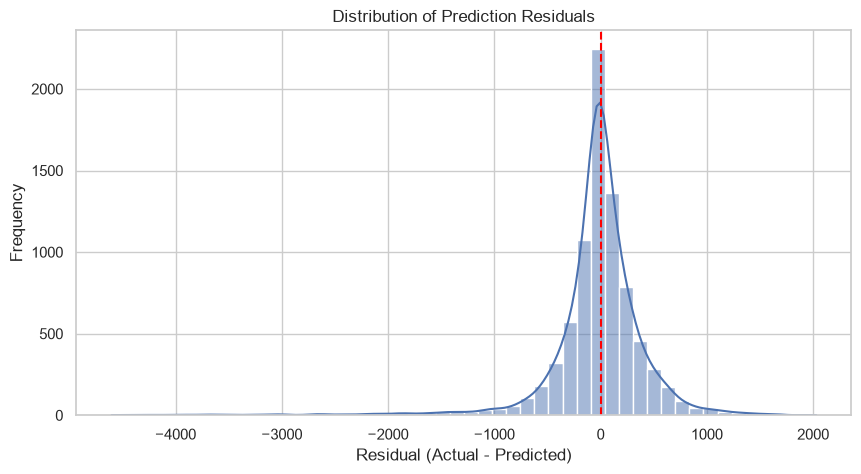

In [80]:
residuals = y_test - y_pred_tuned_weather

plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=50, kde=True)

plt.axvline(0, color="red", linestyle="--")
plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()

In [81]:
print("Residual Statistics")
print("-------------------")
print(f"Mean residual   : {residuals.mean():.2f}")
print(f"Median residual : {residuals.median():.2f}")
print(f"Minimum         : {residuals.min():.2f}")
print(f"Maximum         : {residuals.max():.2f}")
print(f"Std deviation   : {residuals.std():.2f}")

Residual Statistics
-------------------
Mean residual   : -26.79
Median residual : -5.76
Minimum         : -4602.46
Maximum         : 2028.41
Std deviation   : 472.35


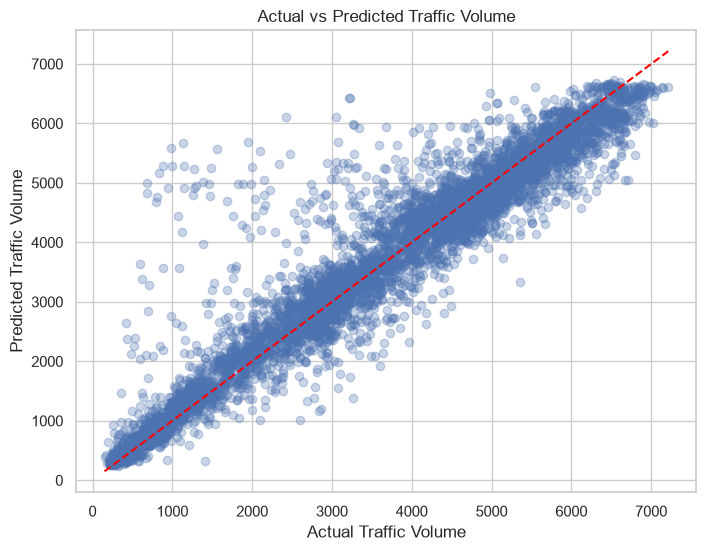

In [82]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_tuned_weather,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.title("Actual vs Predicted Traffic Volume")
plt.xlabel("Actual Traffic Volume")
plt.ylabel("Predicted Traffic Volume")
plt.show()

### Residual Analysis and Actual vs Predicted Comparison

Residual analysis was performed on the best-performing tuned time-plus-weather Random Forest model.

A residual is calculated as:

Residual = Actual Traffic Volume − Predicted Traffic Volume

**Residual distribution observations:**

- Most residuals are concentrated around zero.
- The distribution has a long negative tail, indicating occasional substantial overpredictions.
- The mean residual is -26.79, indicating a slight overall tendency to overpredict.
- The median residual is -5.76, showing that the central prediction error is close to zero.

**Actual vs Predicted observations:**

The scatter plot shows a strong relationship between actual and predicted traffic volumes. Most observations lie relatively close to the ideal prediction line.

However, some observations show considerable deviations, particularly in certain medium and lower traffic-volume ranges. The model also exhibits some underprediction at higher traffic volumes.

Overall, the residual analysis suggests that the model performs well on most observations but struggles with some unusual traffic conditions.

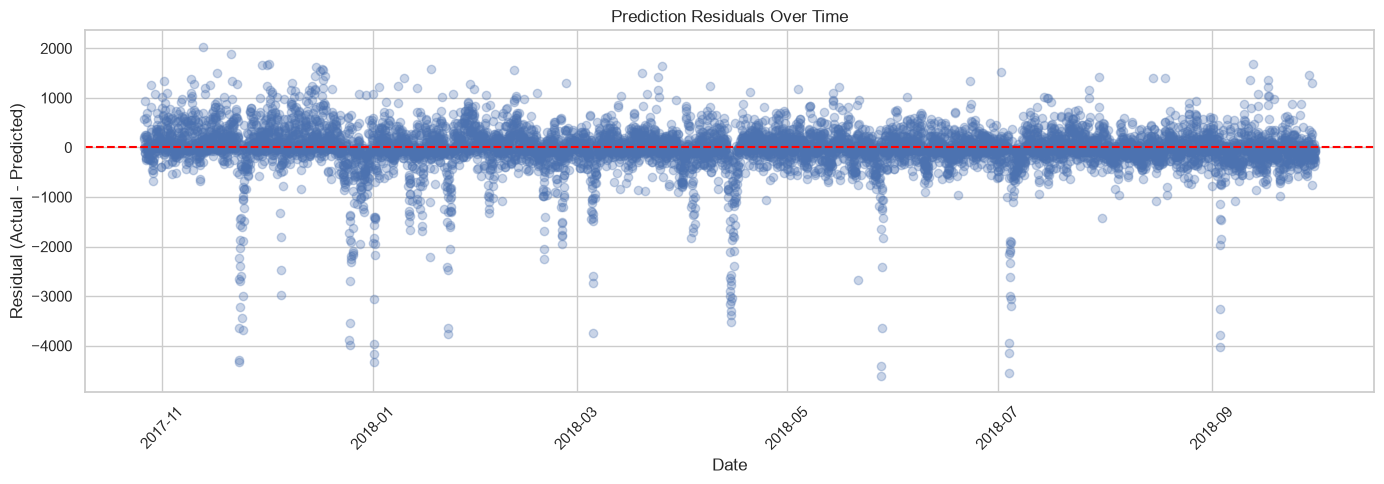

In [83]:
plt.figure(figsize=(14, 5))

plt.scatter(
    test_df["date_time"],
    residuals,
    alpha=0.3
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Prediction Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residual (Actual - Predicted)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Residual Analysis Over Time

The residuals of the tuned time-plus-weather Random Forest model were plotted against the timestamps of the test dataset.

**Observations:**

- Most residuals are concentrated around zero, indicating reasonably accurate predictions for the majority of observations.
- Several clusters of large negative residuals are visible, indicating periods of substantial overprediction.
- Occasional positive residuals indicate underprediction.
- No clear continuous upward or downward drift is observed throughout the test period.

**Interpretation:**

Although the model performs well overall, its errors are not entirely random over time. Certain observations or periods produce unusually large prediction errors.

These errors may be associated with unusual traffic conditions or factors not represented in the available features. Further investigation would be required to identify their causes.

In [84]:
mae_improvement = (
    (mae_tuned_time - mae_tuned_weather)
    / mae_tuned_time
) * 100

rmse_improvement = (
    (rmse_tuned_time - rmse_tuned_weather)
    / rmse_tuned_time
) * 100

r2_improvement = r2_tuned_weather - r2_tuned_time

print("Improvement: Tuned Time + Weather vs Tuned Time-only")
print("-----------------------------------------------------")
print(f"MAE reduction  : {mae_improvement:.2f}%")
print(f"RMSE reduction : {rmse_improvement:.2f}%")
print(f"R² increase    : {r2_improvement:.4f}")

Improvement: Tuned Time + Weather vs Tuned Time-only
-----------------------------------------------------
MAE reduction  : 2.20%
RMSE reduction : 2.74%
R² increase    : 0.0033


### Additional Experiment: Removing the `year` Feature

Random Forest can only split on `year` values seen during training, so it cannot extrapolate to a later year such as 2018 in the test period.
To check whether `year` matters, both **baseline** models (same hyperparameters as Stage 9) are retrained without it and compared with the original baseline results.

In [ ]:
# Ablation: retrain baseline models WITHOUT the "year" feature
time_features_no_year = [f for f in time_features if f != "year"]

# ---- Time-only model (no year) ----
time_pre_ny = ColumnTransformer(
    transformers=[("time", SimpleImputer(strategy="median"), time_features_no_year)],
    remainder="drop"
)

time_model_ny = Pipeline(steps=[
    ("preprocessor", time_pre_ny),
    ("regressor", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

time_model_ny.fit(train_df[time_features_no_year], y_train)
y_pred_time_ny = time_model_ny.predict(test_df[time_features_no_year])

# ---- Time + weather model (no year) ----
weather_pre_ny = Pipeline(steps=[
    ("rainfall_capper", RainfallCapper(column="rain_1h", percentile=99)),
    ("features", ColumnTransformer(
        transformers=[
            ("time", SimpleImputer(strategy="median"), time_features_no_year),
            ("weather_numeric", SimpleImputer(strategy="median"), weather_numeric_features),
            ("holiday", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]), ["holiday"]),
            ("weather_conditions", MultiHotWeatherEncoder(), ["weather_main"])
        ],
        remainder="drop"
    ))
])

weather_cols_ny = time_features_no_year + weather_numeric_features + ["holiday", "weather_main"]

weather_model_ny = Pipeline(steps=[
    ("preprocessor", weather_pre_ny),
    ("regressor", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

weather_model_ny.fit(train_df[weather_cols_ny], y_train)
y_pred_weather_ny = weather_model_ny.predict(test_df[weather_cols_ny])

# ---- Compare with the original baselines (which include year) ----
def scores(y_true, y_pred):
    return (mean_absolute_error(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)),
            r2_score(y_true, y_pred))

rows = {
    "Baseline Time-only (with year)":      (mae_time, rmse_time, r2_time),
    "Baseline Time-only (no year)":        scores(y_test, y_pred_time_ny),
    "Baseline Time + Weather (with year)": (mae_weather, rmse_weather, r2_weather),
    "Baseline Time + Weather (no year)":   scores(y_test, y_pred_weather_ny),
}

year_ablation_df = pd.DataFrame(rows, index=["MAE", "RMSE", "R2"]).T
year_ablation_df.round(4)

### 12. Final Model Comparison

The four Random Forest models were compared using the same chronological test dataset.

The best-performing model was the tuned time-plus-weather Random Forest.

**Final comparison of tuned models:**

| Metric | Time-only | Time + weather |
|---|---:|---:|
| MAE | 275.44 | 269.38 |
| RMSE | 486.41 | 473.08 |
| R² | 0.9390 | 0.9423 |

**Improvement from including weather features:**

- MAE reduction: 2.20%
- RMSE reduction: 2.74%
- R² increase: 0.0033

**Conclusion:**

Adding weather information improved traffic-volume prediction compared with using time-based features alone.

However, the improvement was relatively modest. This suggests that time-based patterns provide most of the predictive information, while weather features offer additional predictive value.

Hyperparameter tuning also improved the performance of both models compared with their baseline versions.

# 13. Conclusion and Future Scope

## Conclusion

This project developed and evaluated machine learning models for predicting traffic volume using historical traffic, time and weather information.

The UCI Metro Interstate Traffic Volume dataset was cleaned and processed before performing exploratory data analysis and feature engineering.

Two Random Forest regression approaches were investigated:

1. A time-only model using engineered time-based features.
2. A time-plus-weather model incorporating numerical and categorical weather information.

Both models were trained using a chronological 80:20 train-test split. Hyperparameter optimization was performed using GridSearchCV with TimeSeriesSplit to preserve temporal ordering during cross-validation.

The tuned time-plus-weather Random Forest achieved the best test performance:

- MAE: 269.38
- RMSE: 473.08
- R²: 0.9423

The addition of weather features reduced MAE by 2.20% and RMSE by 2.74% compared with the tuned time-only model.

The results indicate that time-based features are highly informative for traffic-volume prediction, while weather information provides a modest additional improvement.

## Limitations

- The project uses historical data from a single traffic monitoring location.
- The model does not include road incidents, accidents, construction or special events.
- Only Random Forest regression was investigated.
- The evaluation uses one chronological train-test split.
- Some unusual observations produce large prediction errors.
- The dataset has gaps in hourly coverage (40,575 hourly records across roughly six years), so lag-based features would need careful gap handling.
- The `year` feature cannot generalise to years not seen in training (the test period includes 2018); see the year ablation experiment above.

## Future Scope

- Compare Random Forest with XGBoost, Gradient Boosting and other regression algorithms.
- Investigate additional features such as public holidays, special events and traffic incidents.
- Explore lag-based traffic features using previous traffic observations, ensuring that only information available at prediction time is used.
- Evaluate the model across multiple chronological test periods.
- Develop a web application that allows users to enter time and weather conditions and obtain predicted traffic volume.